# Skripsi
Klasifikasi Penyakit Daun dan Buah Jambu Biji Menggunakan CNN dengan Arsitektur MobileNetV2
*   Nama : Azka Azkia
*   NIM : 2206047



In [ ]:
import os  # Modul bawaan Python untuk berinteraksi dengan sistem operasi (misalnya membuat folder, membaca path file)
import zipfile  # Mengimpor modul untuk membaca dan mengekstrak file berekstensi .zip
import numpy as np  # Mengimpor NumPy, pustaka numerik untuk operasi array dan matriks yang sangat cepat dan efisien
import matplotlib.pyplot as plt  # Mengimpor matplotlib, digunakan untuk menampilkan grafik atau visualisasi citra
import tensorflow as tf  # Mengimpor TensorFlow, pustaka deep learning populer untuk membangun dan melatih model neural network
import seaborn as sns  # Mengimpor seaborn, pustaka visualisasi berbasis matplotlib, biasanya digunakan untuk plot yang lebih menarik (misalnya heatmap confusion matrix)
import random  # Modul bawaan Python untuk menghasilkan nilai acak (random sampling, shuffling data, dsb.)
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_auc_score  # Mengimpor fungsi evaluasi model dari scikit-learn, misalnya untuk membuat classification report, confusion matrix, F1-score, dan ROC AUC
import numpy as np  # Sudah diimpor sebelumnya, ini sebenarnya duplikat (boleh dihapus agar lebih rapi)
import matplotlib.pyplot as plt  # Sudah diimpor sebelumnya, ini juga duplikat (boleh dihapus)
import tensorflow as tf  # Sudah diimpor sebelumnya, ini juga duplikat (boleh dihapus)
from tensorflow.keras.preprocessing.image import ImageDataGenerator  # Mengimpor ImageDataGenerator, digunakan untuk augmentasi citra (rotasi, flip, dsb.) agar dataset lebih bervariasi
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.models import Model  # Untuk membuat atau memodifikasi model Keras
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D  # Mengimpor layer Dense (fully connected) dan GlobalAveragePooling2D yang sering dipakai di CNN
from tensorflow.keras.optimizers import Adam  # Optimizer Adam, salah satu optimizer yang paling umum dipakai untuk deep learning
from google.colab import drive  # Modul khusus Google Colab untuk mengakses file di Google Drive
from PIL import Image  # Mengimpor PIL (Python Imaging Library) untuk membuka, mengedit, atau menyimpan file gambar (format jpg/png/dll)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# # 2. Ekstrak dataset dari zip (pastikan path zip sesuai!)
zip_path = "/content/drive/MyDrive/AzkaAzkia_MachineLearning/UAS_AzkaAzkia/GuavaDetection.zip"  # Menyimpan path lengkap ke file zip dataset (sesuaikan dengan lokasi di Google Drive)
extract_path = "/content/drive/MyDrive/AzkaAzkia_MachineLearning/UAS_AzkaAzkia/GuavaDetection"  # Menentukan lokasi folder tujuan ekstraksi dataset di dalam Colab

# # Membuka file zip dan mengekstrak semua isinya ke folder yang ditentukan
with zipfile.ZipFile(zip_path, 'r') as zip_ref:  # Membuka file zip dalam mode 'read'
   zip_ref.extractall(extract_path)  # Mengekstrak seluruh isi file zip ke path yang telah ditentukan

In [ ]:
base_dir = "/content/drive/MyDrive/AzkaAzkia_MachineLearning/UAS_AzkaAzkia/GuavaDetection" # Path folder utama dataset di Google Drive
train_dir = os.path.join(base_dir, "train") # Path ke folder data latih
valid_dir = os.path.join(base_dir, "valid") # Path ke folder data validasi

## SAMPLE

In [ ]:
# 1. SAMPLE
# =====================================================
# LOKASI DATASET
# =====================================================

base_dir = "/content/drive/MyDrive/AzkaAzkia_MachineLearning/UAS_AzkaAzkia/GuavaDetection" # Menentukan direktori utama dataset penyakit daun dan buah jambu biji

# Menentukan lokasi dataset untuk masing-masing subset
train_dir = os.path.join(base_dir, "train")
valid_dir = os.path.join(base_dir, "valid")
test_dir  = os.path.join(base_dir, "test")

IMG_SIZE = (224, 224) # Menentukan ukuran citra yang digunakan sebagai input model
BATCH_SIZE = 32 # Menentukan jumlah citra yang diproses dalam satu batch
SEED = 42 # Menetapkan seed untuk menjaga konsistensi proses yang bersifat acak

In [ ]:
# =====================================================
# VERIFIKASI DATASET
# =====================================================

# emeriksa keberadaan direktori dataset pada masing-masing subset
print("Train :", os.path.exists(train_dir))
print("Validation :", os.path.exists(valid_dir))
print("Test :", os.path.exists(test_dir))

Train : True
Validation : True
Test : True


In [ ]:
# Buang kelas "Unlabeled" jika ada
def remove_unlabeled(directory): # Mendefinisikan fungsi untuk menghapus folder bernama 'Unlabeled' di dalam directory tertentu
    unlabeled_path = os.path.join(directory, "Unlabeled") # Membuat path lengkap ke folder 'Unlabeled'
    if os.path.exists(unlabeled_path):  # Mengecek apakah folder 'Unlabeled' benar-benar ada
        print(f"Menghapus folder: {unlabeled_path}") # Memberi pesan di console bahwa folder akan dihapus
        import shutil # Mengimpor modul shutil untuk operasi file/folder
        shutil.rmtree(unlabeled_path) # Menghapus folder 'Unlabeled' beserta isinya

remove_unlabeled(train_dir) # Memanggil fungsi untuk menghapus folder 'Unlabeled' di dataset training
remove_unlabeled(valid_dir)  # Memanggil fungsi untuk menghapus folder 'Unlabeled' di dataset validasi

Menghapus folder: /content/drive/MyDrive/AzkaAzkia_MachineLearning/UAS_AzkaAzkia/GuavaDetection/train/Unlabeled
Menghapus folder: /content/drive/MyDrive/AzkaAzkia_MachineLearning/UAS_AzkaAzkia/GuavaDetection/valid/Unlabeled


In [ ]:
# =====================================================
# INFORMASI KELAS
# =====================================================

# Mengambil nama folder kelas yang terdapat pada dataset training
# dan mengurutkannya secara alfabetis untuk menjaga urutan kelas tetap konsisten
classes = sorted([
    folder
    for folder in os.listdir(train_dir)
    if os.path.isdir(os.path.join(train_dir, folder))
])

# Menampilkan jumlah kelas yang digunakan dalam penelitian
print("Jumlah Kelas :", len(classes))
print()

# Menampilkan nama setiap kelas beserta nomor urutnya
for i, cls in enumerate(classes, start=1):
    print(f"{i}. {cls}")

Jumlah Kelas : 9

1. Anthracnose 224
2. Canker 224
3. Dot 224
4. Fruit Fly 224
5. Healthy Fruit 224
6. Phytophora 224
7. Red Rust 224
8. Scab 224
9. Styler and Root 224


In [ ]:
import pandas as pd # Mengimpor library Pandas untuk mengolah dan menampilkan data dalam bentuk tabel

# =====================================
# INFORMASI DATASET
# =====================================

dataset_info = [] # Membuat list kosong untuk menyimpan informasi jumlah citra setiap kelas

for kelas in classes: # Melakukan perulangan untuk setiap kelas yang terdapat pada dataset

    train_total = len(os.listdir(os.path.join(train_dir, kelas))) # Menghitung jumlah citra pada data training
    valid_total = len(os.listdir(os.path.join(valid_dir, kelas))) # Menghitung jumlah citra pada data validation
    test_total  = len(os.listdir(os.path.join(test_dir, kelas))) # Menghitung jumlah citra pada data testing

    total = train_total + valid_total + test_total # Menghitung total citra dari seluruh subset pada setiap kelas

    dataset_info.append([ # Menyimpan informasi jumlah data setiap kelas ke dalam list
        kelas, # Menyimpan nama kelas
        train_total, # Menyimpan jumlah data training
        valid_total, # Menyimpan jumlah data validation
        test_total, # Menyimpan jumlah data testing
        total # Menyimpan jumlah keseluruhan data
    ])

dataset_df = pd.DataFrame( # Mengubah informasi dataset menjadi DataFrame
    dataset_info, # Menggunakan data informasi yang telah dikumpulkan
    columns=[ # Menentukan nama kolom pada tabel
        "Class", # Nama kelas
        "Train", # Jumlah data training
        "Validation", # Jumlah data validation
        "Test", # Jumlah data testing
        "Total" # Total keseluruhan data
    ]
)

dataset_df # Menampilkan tabel informasi jumlah dataset pada setiap kelas

,Class,Train,Validation,Test,Total
0,Anthracnose 224,523,128,85,736
1,Canker 224,138,39,15,192
2,Dot 224,152,37,20,209
3,Fruit Fly 224,331,85,43,459
4,Healthy Fruit 224,178,52,25,255
5,Phytophora 224,44,12,9,65
6,Red Rust 224,125,38,27,190
7,Scab 224,78,21,15,114
8,Styler and Root 224,195,67,25,287


In [ ]:
# =====================================
# RINGKASAN DATASET
# =====================================

total_train = dataset_df["Train"].sum() # Menghitung total seluruh citra pada dataset training
total_valid = dataset_df["Validation"].sum() # Menghitung total seluruh citra pada dataset validation
total_test  = dataset_df["Test"].sum() # Menghitung total seluruh citra pada dataset testing

total_dataset = ( # Menghitung jumlah keseluruhan citra dalam dataset
    total_train + # Menambahkan seluruh data training
    total_valid + # Menambahkan seluruh data validation
    total_test # Menambahkan seluruh data testing
)

print("="*40) # Menampilkan garis pemisah untuk memperjelas tampilan output
print("RINGKASAN DATASET") # Menampilkan judul ringkasan dataset
print("="*40) # Menampilkan garis pemisah

print("Jumlah Kelas      :", len(classes)) # Menampilkan jumlah kelas yang digunakan
print("Jumlah Train      :", total_train) # Menampilkan jumlah seluruh data training
print("Jumlah Validation :", total_valid) # Menampilkan jumlah seluruh data validation
print("Jumlah Test       :", total_test) # Menampilkan jumlah seluruh data testing
print("Total Dataset     :", total_dataset) # Menampilkan jumlah keseluruhan citra

RINGKASAN DATASET
Jumlah Kelas      : 9
Jumlah Train      : 1764
Jumlah Validation : 479
Jumlah Test       : 264
Total Dataset     : 2507


## EXPLORE

In [ ]:
# =====================================================
# DISTRIBUSI DATASET PER KELAS
# =====================================================

distribution = [] # Membuat list kosong untuk menyimpan informasi distribusi data setiap kelas

for cls in classes: # Melakukan perulangan untuk setiap kelas dalam dataset

    train_count = len(os.listdir(os.path.join(train_dir, cls))) # Menghitung jumlah citra pada subset training
    valid_count = len(os.listdir(os.path.join(valid_dir, cls))) # Menghitung jumlah citra pada subset validation
    test_count = len(os.listdir(os.path.join(test_dir, cls))) # Menghitung jumlah citra pada subset testing

    distribution.append({ # Menyimpan hasil perhitungan distribusi data setiap kelas
        "Class": cls, # Menyimpan nama kelas
        "Train": train_count, # Menyimpan jumlah data training
        "Validation": valid_count, # Menyimpan jumlah data validation
        "Test": test_count, # Menyimpan jumlah data testing
        "Total": train_count + valid_count + test_count # Menghitung total data pada setiap kelas
    })

distribution_df = pd.DataFrame(distribution) # Mengubah hasil distribusi menjadi DataFrame

distribution_df # Menampilkan tabel distribusi dataset setiap kelas

,Class,Train,Validation,Test,Total
0,Anthracnose 224,523,128,85,736
1,Canker 224,138,39,15,192
2,Dot 224,152,37,20,209
3,Fruit Fly 224,331,85,43,459
4,Healthy Fruit 224,178,52,25,255
5,Phytophora 224,44,12,9,65
6,Red Rust 224,125,38,27,190
7,Scab 224,78,21,15,114
8,Styler and Root 224,195,67,25,287


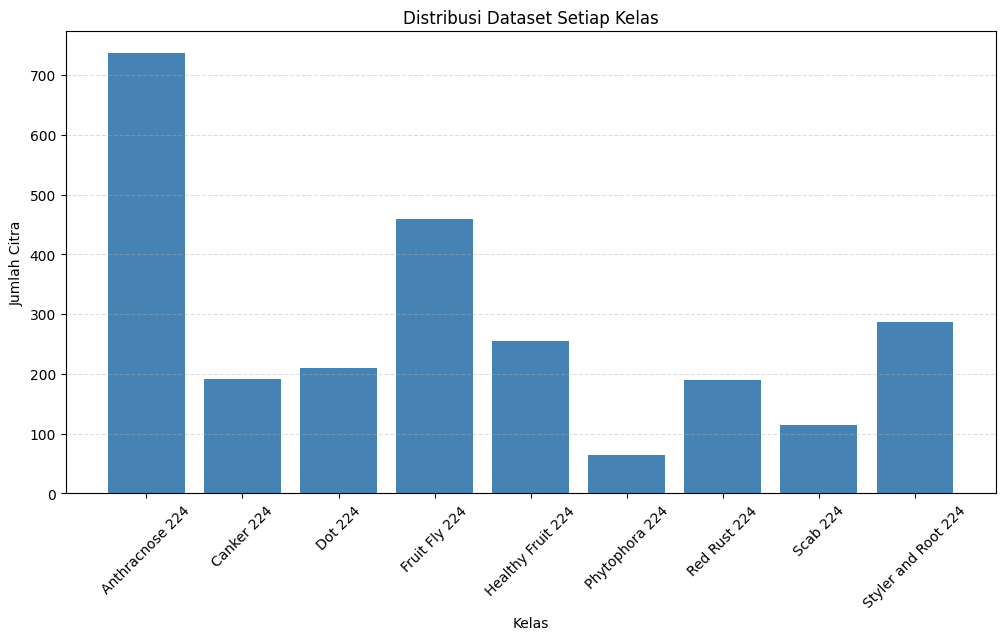

In [ ]:
# =====================================================
# VISUALISASI DISTRIBUSI DATASET
# =====================================================

plt.figure(figsize=(12,6)) # Membuat area grafik dengan ukuran 12 x 6 inci

plt.bar(
    distribution_df["Class"], # Menetapkan nama kelas sebagai sumbu X
    distribution_df["Total"], # Menetapkan jumlah total citra sebagai sumbu Y
    color="steelblue" # Menentukan warna batang pada grafik
)

plt.xticks(rotation=45) # Memutar label kelas sebesar 45 derajat agar lebih mudah dibaca

plt.ylabel("Jumlah Citra") # Memberikan label pada sumbu Y

plt.xlabel("Kelas") # Memberikan label pada sumbu X

plt.title("Distribusi Dataset Setiap Kelas") # Memberikan judul pada grafik

plt.grid(axis='y', linestyle='--', alpha=0.4) # Menambahkan garis bantu horizontal pada sumbu Y

plt.show() # Menampilkan grafik distribusi dataset

In [ ]:
# =====================================================
# PERSENTASE DATASET
# =====================================================

distribution_df["Persentase (%)"] = ( # Menghitung persentase jumlah citra pada setiap kelas
    distribution_df["Total"] / # Mengambil jumlah total citra pada masing-masing kelas
    distribution_df["Total"].sum() # Membagi dengan jumlah keseluruhan citra dalam dataset
) * 100 # Mengubah hasil perhitungan menjadi persentase

distribution_df # Menampilkan tabel distribusi beserta persentase setiap kelas

,Class,Train,Validation,Test,Total,Persentase (%)
0,Anthracnose 224,523,128,85,736,29.357798
1,Canker 224,138,39,15,192,7.658556
2,Dot 224,152,37,20,209,8.336657
3,Fruit Fly 224,331,85,43,459,18.308736
4,Healthy Fruit 224,178,52,25,255,10.171520
5,Phytophora 224,44,12,9,65,2.592740
6,Red Rust 224,125,38,27,190,7.578779
7,Scab 224,78,21,15,114,4.547268
8,Styler and Root 224,195,67,25,287,11.447946


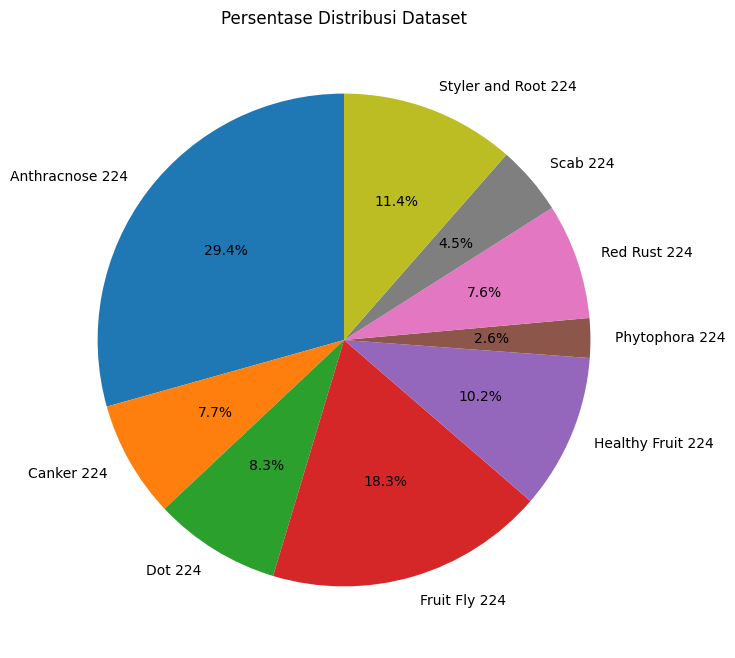

In [ ]:
# =====================================================
# PIE CHART
# =====================================================

plt.figure(figsize=(8,8)) # Membuat area grafik dengan ukuran 8 x 8 inci

plt.pie(
    distribution_df["Total"], # Menggunakan jumlah total citra setiap kelas sebagai nilai pie chart
    labels=distribution_df["Class"], # Menampilkan nama kelas sebagai label pada setiap bagian
    autopct='%1.1f%%', # Menampilkan persentase setiap kelas dengan satu angka desimal
    startangle=90 # Menentukan posisi awal pie chart pada sudut 90 derajat
)

plt.title("Persentase Distribusi Dataset") # Memberikan judul pada diagram

plt.show() # Menampilkan pie chart

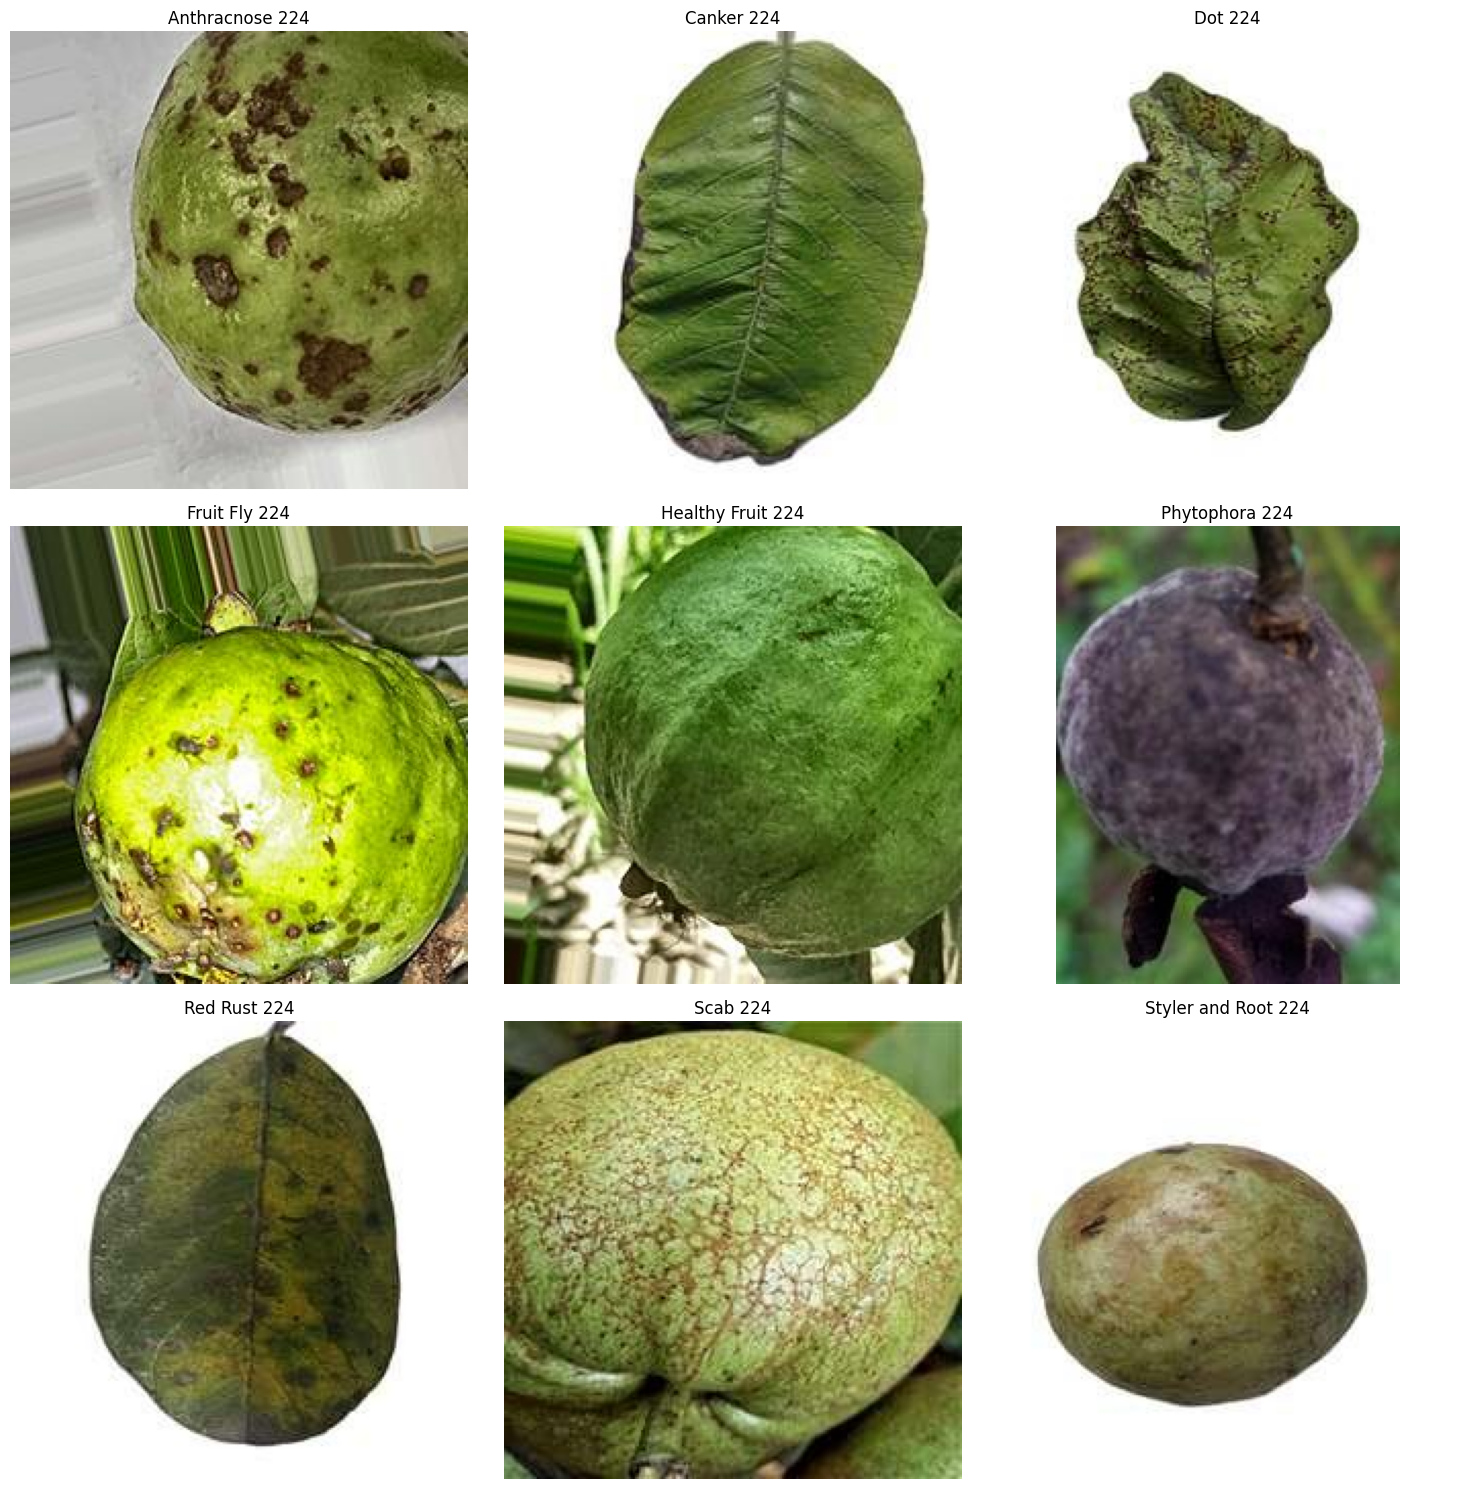

In [ ]:
# =====================================================
# CONTOH GAMBAR SETIAP KELAS
# =====================================================

fig, axes = plt.subplots(3,3, figsize=(15,15)) # Membuat grid 3x3 untuk menampilkan 9 kelas citra

axes = axes.flatten() # Mengubah array axes menjadi satu dimensi agar mudah digunakan dalam perulangan

for i, cls in enumerate(classes): # Melakukan perulangan untuk setiap kelas dataset

    folder = os.path.join(train_dir, cls) # Menentukan folder yang berisi citra dari kelas yang sedang diproses

    image_name = random.choice(os.listdir(folder)) # Memilih satu citra secara acak dari folder kelas

    image_path = os.path.join(folder, image_name) # Membentuk lokasi lengkap file citra

    image = Image.open(image_path) # Membuka citra menggunakan library PIL

    axes[i].imshow(image) # Menampilkan citra pada posisi subplot sesuai indeks kelas

    axes[i].set_title(cls) # Menampilkan nama kelas sebagai judul setiap citra

    axes[i].axis("off") # Menyembunyikan sumbu koordinat agar tampilan citra lebih jelas

plt.tight_layout() # Mengatur jarak antar subplot agar tidak saling bertumpuk

plt.show() # Menampilkan seluruh citra dari setiap kelas

In [ ]:
# =====================================================
# UKURAN CITRA
# =====================================================

image_sizes = [] # Membuat list kosong untuk menyimpan ukuran setiap citra

for cls in classes: # Melakukan perulangan pada seluruh kelas dataset

    folder = os.path.join(train_dir, cls) # Menentukan folder citra berdasarkan kelas

    for img_name in os.listdir(folder)[:20]: # Mengambil maksimal 20 citra dari setiap kelas sebagai sampel analisis

        img_path = os.path.join(folder, img_name) # Menentukan lokasi lengkap file citra

        img = Image.open(img_path) # Membuka citra menggunakan library PIL

        image_sizes.append(img.size) # Menyimpan ukuran citra berupa lebar dan tinggi ke dalam list

size_df = pd.DataFrame( # Membuat DataFrame berdasarkan informasi ukuran citra
    image_sizes, # Menggunakan data ukuran citra yang telah dikumpulkan
    columns=["Width","Height"] # Menentukan kolom lebar dan tinggi citra
)

size_df.describe() # Menampilkan statistik deskriptif ukuran citra

,Width,Height
count,180.000000,180.000000
mean,219.738889,223.027778
std,17.390155,5.252752
min,116.000000,171.000000
25%,224.000000,224.000000
50%,224.000000,224.000000
75%,224.000000,224.000000
max,224.000000,224.000000


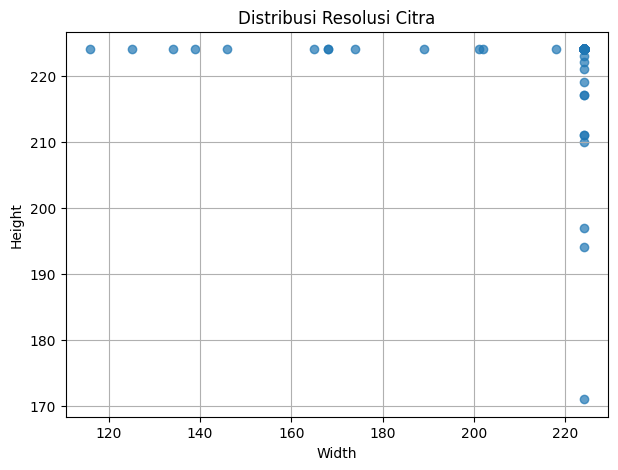

In [ ]:
# =====================================================
# DISTRIBUSI RESOLUSI
# =====================================================

plt.figure(figsize=(7,5)) # Membuat area grafik dengan ukuran 7 x 5 inci

plt.scatter(
    size_df["Width"], # Menggunakan lebar citra sebagai nilai pada sumbu X
    size_df["Height"], # Menggunakan tinggi citra sebagai nilai pada sumbu Y
    alpha=0.7 # Mengatur tingkat transparansi titik agar distribusi lebih mudah diamati
)

plt.xlabel("Width") # Memberikan label pada sumbu X untuk menunjukkan lebar citra

plt.ylabel("Height") # Memberikan label pada sumbu Y untuk menunjukkan tinggi citra

plt.title("Distribusi Resolusi Citra") # Memberikan judul pada grafik

plt.grid(True) # Menambahkan garis bantu untuk memudahkan pembacaan posisi titik

plt.show() # Menampilkan grafik distribusi resolusi citra

In [ ]:
# =====================================================
# ANALISIS FORMAT FILE SELURUH DATASET
# =====================================================

from collections import Counter # Mengimpor Counter untuk menghitung jumlah setiap format file

formats = Counter() # Membuat objek Counter untuk menyimpan frekuensi setiap format file

folders = { # Membuat dictionary yang berisi lokasi masing-masing subset dataset
    "Train": train_dir, # Menyimpan lokasi dataset training
    "Validation": valid_dir, # Menyimpan lokasi dataset validation
    "Test": test_dir # Menyimpan lokasi dataset testing
}

for folder_name, folder_path in folders.items(): # Melakukan perulangan pada setiap subset dataset

    for cls in classes: # Melakukan perulangan pada setiap kelas

        class_path = os.path.join(folder_path, cls) # Menentukan lokasi folder berdasarkan subset dan kelas

        for file in os.listdir(class_path): # Membaca seluruh file yang terdapat pada folder kelas

            ext = os.path.splitext(file)[1].lower() # Mengambil ekstensi file dan mengubahnya menjadi huruf kecil

            formats[ext] += 1 # Menghitung jumlah kemunculan setiap format file

format_df = pd.DataFrame( # Mengubah hasil perhitungan format file menjadi DataFrame
    formats.items(), # Menggunakan pasangan format dan jumlah file yang telah dihitung
    columns=["Format", "Jumlah"] # Menentukan nama kolom tabel
)

format_df # Menampilkan tabel distribusi format file pada seluruh dataset

,Format,Jumlah
0,.jpg,2507


In [ ]:
# =====================================================
# ANALISIS IMBALANCE
# =====================================================

max_class = distribution_df.loc[ # Mengambil data kelas dengan jumlah citra terbanyak
    distribution_df["Total"].idxmax() # Menentukan indeks kelas dengan nilai Total maksimum
]

min_class = distribution_df.loc[ # Mengambil data kelas dengan jumlah citra tersedikit
    distribution_df["Total"].idxmin() # Menentukan indeks kelas dengan nilai Total minimum
]

print("="*50) # Menampilkan garis pemisah pada output

print("Kelas Terbanyak") # Menampilkan informasi mengenai kelas dengan jumlah citra terbanyak

print(max_class) # Menampilkan nama kelas beserta jumlah data dan persentasenya

print() # Memberikan jarak antar informasi pada output

print("Kelas Tersedikit") # Menampilkan informasi mengenai kelas dengan jumlah citra tersedikit

print(min_class) # Menampilkan nama kelas beserta jumlah data dan persentasenya

Kelas Terbanyak
Class             Anthracnose 224
Train                         523
Validation                    128
Test                           85
Total                         736
Persentase (%)          29.357798
Name: 0, dtype: object

Kelas Tersedikit
Class             Phytophora 224
Train                         44
Validation                    12
Test                           9
Total                         65
Persentase (%)           2.59274
Name: 5, dtype: object


In [ ]:
# =====================================================
# STATISTIK DATASET
# =====================================================

distribution_df.describe() # Menampilkan statistik deskriptif jumlah data pada setiap kelas

,Train,Validation,Test,Total,Persentase (%)
count,9.000000,9.000000,9.000000,9.000000,9.000000
mean,196.000000,53.222222,29.333333,278.555556,11.111111
std,146.989796,35.755341,23.021729,204.724883,8.166130
min,44.000000,12.000000,9.000000,65.000000,2.592740
25%,125.000000,37.000000,15.000000,190.000000,7.578779
50%,152.000000,39.000000,25.000000,209.000000,8.336657
75%,195.000000,67.000000,27.000000,287.000000,11.447946
max,523.000000,128.000000,85.000000,736.000000,29.357798


## MODIFY

In [ ]:
# =====================================================
# MODIFY
# IMPORT LIBRARY PREPROCESSING
# =====================================================

import tensorflow as tf # Mengimpor TensorFlow sebagai framework utama untuk pengolahan dan pembangunan model

from tensorflow.keras.preprocessing.image import ImageDataGenerator # Mengimpor ImageDataGenerator untuk preprocessing dan augmentasi citra

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input # Mengimpor fungsi preprocessing yang sesuai dengan MobileNetV2

from sklearn.utils.class_weight import compute_class_weight # Mengimpor fungsi untuk menghitung bobot masing-masing kelas

import numpy as np # Mengimpor NumPy untuk operasi numerik dan pengolahan array

In [ ]:
# =====================================================
# PARAMETER MODEL
# =====================================================

IMG_SIZE = (224,224) # Menentukan ukuran citra menjadi 224x224 piksel sesuai dengan ukuran input MobileNetV2

BATCH_SIZE = 32 # Menentukan jumlah citra yang diproses dalam satu batch

SEED = 42 # Menentukan nilai random seed untuk menjaga konsistensi proses pengacakan data

print("Ukuran Gambar :", IMG_SIZE) # Menampilkan ukuran citra yang digunakan

print("Batch Size :", BATCH_SIZE) # Menampilkan ukuran batch yang digunakan

print("Random Seed :", SEED) # Menampilkan nilai random seed yang digunakan

Ukuran Gambar : (224, 224)
Batch Size : 32
Random Seed : 42


In [ ]:
# =====================================================
# DATA AUGMENTATION
# =====================================================

train_datagen = ImageDataGenerator( # Membuat generator untuk preprocessing dan augmentasi data training

    preprocessing_function=preprocess_input, # Melakukan preprocessing citra sesuai kebutuhan MobileNetV2

    rotation_range=20, # Melakukan rotasi citra secara acak hingga 20 derajat

    width_shift_range=0.2, # Menggeser posisi citra secara horizontal hingga 20% dari lebar citra

    height_shift_range=0.2, # Menggeser posisi citra secara vertikal hingga 20% dari tinggi citra

    zoom_range=0.2, # Melakukan zoom secara acak hingga 20%

    shear_range=0.2, # Memberikan transformasi shear hingga 20%

    horizontal_flip=True, # Membalik citra secara horizontal secara acak

    fill_mode='nearest' # Mengisi area kosong akibat transformasi menggunakan nilai piksel terdekat

)

valid_datagen = ImageDataGenerator( # Membuat generator untuk data validation tanpa augmentasi

    preprocessing_function=preprocess_input # Melakukan preprocessing citra sesuai dengan kebutuhan MobileNetV2

)

test_datagen = ImageDataGenerator( # Membuat generator untuk data testing tanpa augmentasi

    preprocessing_function=preprocess_input # Melakukan preprocessing citra sesuai dengan kebutuhan MobileNetV2

)

In [ ]:
# =====================================================
# MEMBANGUN DATA GENERATOR
# =====================================================

train_generator = train_datagen.flow_from_directory( # Membuat generator untuk membaca dan memproses data training

    train_dir, # Menentukan direktori dataset training

    target_size=IMG_SIZE, # Mengubah ukuran seluruh citra menjadi 224x224 piksel

    batch_size=BATCH_SIZE, # Menentukan jumlah citra yang diproses dalam satu batch

    class_mode='categorical', # Menggunakan label kategorikal untuk klasifikasi multi-kelas

    shuffle=True, # Mengacak data training pada setiap proses pelatihan

    seed=SEED # Menggunakan seed yang telah ditentukan untuk menjaga konsistensi pengacakan

)

valid_generator = valid_datagen.flow_from_directory( # Membuat generator untuk membaca dan memproses data validation

    valid_dir, # Menentukan direktori dataset validation

    target_size=IMG_SIZE, # Mengubah ukuran seluruh citra menjadi 224x224 piksel

    batch_size=BATCH_SIZE, # Menentukan jumlah citra yang diproses dalam satu batch

    class_mode='categorical', # Menggunakan label kategorikal untuk klasifikasi multi-kelas

    shuffle=False # Tidak mengacak data validation agar urutan data tetap konsisten saat evaluasi

)

test_generator = test_datagen.flow_from_directory( # Membuat generator untuk membaca dan memproses data testing

    test_dir, # Menentukan direktori dataset testing

    target_size=IMG_SIZE, # Mengubah ukuran seluruh citra menjadi 224x224 piksel

    batch_size=BATCH_SIZE, # Menentukan jumlah citra yang diproses dalam satu batch

    class_mode='categorical', # Menggunakan label kategorikal untuk klasifikasi multi-kelas

    shuffle=False # Tidak mengacak data testing agar urutan label sesuai dengan hasil prediksi saat evaluasi

)

Found 1764 images belonging to 9 classes.
Found 479 images belonging to 9 classes.
Found 268 images belonging to 10 classes.


In [ ]:
import os # Mengimpor module os untuk berinteraksi dengan sistem operasi

print(os.listdir(test_dir)) # Menampilkan daftar file dan folder yang ada di dalam direktori test_dir

['Anthracnose 224', 'Canker 224', 'Dot 224', 'Fruit Fly 224', 'Healthy Fruit 224', 'Phytophora 224', 'Red Rust 224', 'Scab 224', 'Styler and Root 224', 'Unlabeled']


In [ ]:
import os # Mengimpor module os untuk mengelola file dan direktori

unlabeled_test = os.path.join(test_dir, "Unlabeled") # Membuat path menuju folder "Unlabeled" di dalam test_dir

print(os.path.exists(unlabeled_test)) # Mengecek apakah folder/file tersebut ada dan menampilkan hasil True atau False

True


In [ ]:
import shutil # Mengimpor module shutil untuk mengelola file dan folder

shutil.rmtree(unlabeled_test)  # Menghapus folder "Unlabeled" beserta seluruh isi di dalamnya

In [ ]:
test_generator = test_datagen.flow_from_directory( # Membuat generator data untuk mengambil gambar dari folder test

    test_dir, # Menentukan direktori yang berisi data gambar untuk pengujian
    target_size=IMG_SIZE, # Mengubah ukuran setiap gambar sesuai dengan ukuran yang ditentukan pada IMG_SIZE
    batch_size=BATCH_SIZE, # Menentukan jumlah gambar yang diproses dalam setiap batch
    class_mode='categorical', # Menggunakan label kategori dalam bentuk one-hot encoding
    shuffle=False # Tidak mengacak urutan gambar agar urutan prediksi tetap sesuai dengan data asli
)

Found 264 images belonging to 9 classes.


In [ ]:
train_generator = train_datagen.flow_from_directory( # Membuat generator data untuk mengambil gambar dari folder training
    train_dir, # Menentukan direktori yang berisi data training
    target_size=IMG_SIZE, # Mengubah ukuran gambar sesuai dengan ukuran yang ditentukan pada IMG_SIZE
    batch_size=BATCH_SIZE, # Menentukan jumlah gambar yang diproses dalam setiap batch
    class_mode='categorical', # Menggunakan label kelas dalam bentuk one-hot encoding
    shuffle=True, # Mengacak urutan data training agar model tidak menghafal urutan data
    seed=SEED # Menentukan nilai seed agar proses pengacakan data tetap konsisten
)

valid_generator = valid_datagen.flow_from_directory( # Membuat generator data untuk data validasi
    valid_dir, # Menentukan direktori yang berisi data validasi
    target_size=IMG_SIZE, # Mengubah ukuran gambar sesuai dengan IMG_SIZE
    batch_size=BATCH_SIZE, # Menentukan jumlah gambar yang diproses dalam setiap batch
    class_mode='categorical', # Menggunakan label kelas dalam bentuk one-hot encoding
    shuffle=False # Tidak mengacak data agar urutan data tetap konsisten saat evaluasi
)

test_generator = test_datagen.flow_from_directory( # Membuat generator data untuk data pengujian
    test_dir, # Menentukan direktori yang berisi data testing
    target_size=IMG_SIZE, # Mengubah ukuran gambar sesuai dengan IMG_SIZE
    batch_size=BATCH_SIZE, # Menentukan jumlah gambar yang diproses dalam setiap batch
    class_mode='categorical', # Menggunakan label kelas dalam bentuk one-hot encoding
    shuffle=False # Tidak mengacak data agar urutan prediksi sesuai dengan data asli
)

Found 1764 images belonging to 9 classes.
Found 479 images belonging to 9 classes.
Found 264 images belonging to 9 classes.


In [ ]:
# =====================================================
# INFORMASI GENERATOR
# =====================================================

print("Jumlah Kelas :", train_generator.num_classes) # Menampilkan jumlah kelas yang terdapat pada dataset

print("Jumlah Data Train :", train_generator.samples) # Menampilkan jumlah gambar yang digunakan untuk data training

print("Jumlah Data Validation :", valid_generator.samples) # Menampilkan jumlah gambar yang digunakan untuk data validasi

print("Jumlah Data Test :", test_generator.samples) # Menampilkan jumlah gambar yang digunakan untuk data testing

Jumlah Kelas : 9
Jumlah Data Train : 1764
Jumlah Data Validation : 479
Jumlah Data Test : 264


In [ ]:
# =====================================================
# CLASS WEIGHT
# =====================================================

classes = np.unique(train_generator.classes) # Mendapatkan daftar kelas unik dari data training

weights = compute_class_weight( # Menghitung bobot untuk setiap kelas agar data yang tidak seimbang dapat ditangani

    class_weight="balanced", # Menggunakan metode balanced agar bobot disesuaikan berdasarkan jumlah data setiap kelas

    classes=classes, # Menentukan kelas-kelas yang akan dihitung bobotnya

    y=train_generator.classes # Menggunakan label kelas dari data training sebagai dasar perhitungan bobot

)

class_weights = dict(zip(classes, weights)) # Menggabungkan nomor kelas dengan bobotnya ke dalam dictionary

class_weights # Menampilkan nilai bobot untuk masing-masing kelas

{np.int32(0): np.float64(0.37476099426386233),
 np.int32(1): np.float64(1.4202898550724639),
 np.int32(2): np.float64(1.2894736842105263),
 np.int32(3): np.float64(0.5921450151057401),
 np.int32(4): np.float64(1.101123595505618),
 np.int32(5): np.float64(4.454545454545454),
 np.int32(6): np.float64(1.568),
 np.int32(7): np.float64(2.5128205128205128),
 np.int32(8): np.float64(1.005128205128205)}

In [ ]:
# =====================================================
# TABEL CLASS WEIGHT
# =====================================================

import pandas as pd # Mengimpor library pandas untuk membuat dan mengolah tabel

weight_df = pd.DataFrame({ # Membuat DataFrame untuk menampilkan class weight dalam bentuk tabel

    "Class": train_generator.class_indices.keys(), # Mengambil nama setiap kelas dari generator training

    "Weight": class_weights.values() # Mengambil nilai bobot untuk masing-masing kelas

})

weight_df # Menampilkan tabel class weight

,Class,Weight
0,Anthracnose 224,0.374761
1,Canker 224,1.420290
2,Dot 224,1.289474
3,Fruit Fly 224,0.592145
4,Healthy Fruit 224,1.101124
5,Phytophora 224,4.454545
6,Red Rust 224,1.568000
7,Scab 224,2.512821
8,Styler and Root 224,1.005128


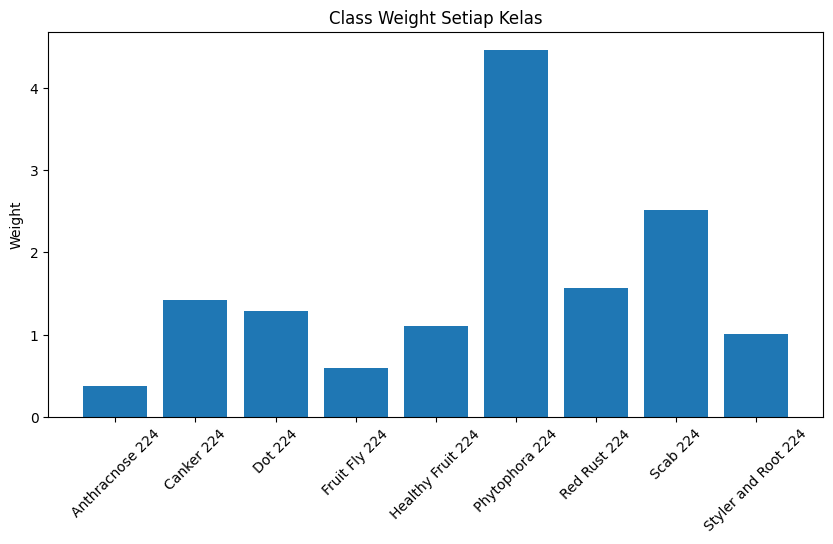

In [ ]:
# =====================================================
# VISUALISASI CLASS WEIGHT
# =====================================================

plt.figure(figsize=(10,5)) # Menentukan ukuran gambar grafik dengan lebar 10 dan tinggi 5

plt.bar( # Membuat grafik batang untuk membandingkan bobot setiap kelas

    weight_df["Class"], # Menentukan nama kelas sebagai sumbu X

    weight_df["Weight"] # Menentukan nilai class weight sebagai sumbu Y

)

plt.xticks(rotation=45) # Memutar label kelas sebesar 45 derajat agar lebih mudah dibaca

plt.ylabel("Weight") # Memberikan label pada sumbu Y sebagai "Weight"

plt.title("Class Weight Setiap Kelas") # Memberikan judul pada grafik

plt.show() # Menampilkan grafik

## MODEL

In [ ]:
# =====================================================
# MODEL
# IMPORT LIBRARY
# =====================================================

from tensorflow.keras.applications import MobileNetV2 # Mengimpor arsitektur MobileNetV2 yang telah dilatih sebelumnya

from tensorflow.keras.layers import ( # Mengimpor layer yang akan digunakan untuk membangun model
    Dense, # Layer untuk menghasilkan output dan melakukan klasifikasi
    Dropout, # Layer untuk mengurangi risiko overfitting dengan menonaktifkan sebagian neuron
    GlobalAveragePooling2D, # Mengubah feature map menjadi satu nilai rata-rata untuk setiap channel
    BatchNormalization # Menormalkan output layer agar proses training lebih stabil
)

from tensorflow.keras.models import Model # Mengimpor Model untuk membuat model dengan arsitektur custom

from tensorflow.keras.optimizers import Adam # Mengimpor optimizer Adam untuk mengoptimalkan proses pembelajaran model

from tensorflow.keras.callbacks import ( # Mengimpor callback untuk mengontrol dan memantau proses training
    EarlyStopping, # Menghentikan training jika performa model tidak mengalami peningkatan
    ReduceLROnPlateau, # Mengurangi learning rate ketika performa model berhenti meningkat
    ModelCheckpoint # Menyimpan model terbaik selama proses training
)

In [ ]:
# =====================================================
# MEMBANGUN BASE MODEL
# =====================================================

base_model = MobileNetV2( # Membuat model dasar menggunakan arsitektur MobileNetV2

    weights="imagenet", # Menggunakan bobot pretrained yang telah dilatih menggunakan dataset ImageNet

    include_top=False, # Menghilangkan layer klasifikasi bawaan MobileNetV2 agar dapat menggunakan layer klasifikasi sendiri

    input_shape=(224,224,3) # Menentukan ukuran input gambar: 224x224 piksel dengan 3 channel warna RGB

)

base_model.summary() # Menampilkan ringkasan arsitektur dan jumlah parameter pada base model

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 2,223,872 (8.48 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [ ]:
# =====================================================
# FREEZE LAYER
# =====================================================

for layer in base_model.layers: # Melakukan perulangan pada seluruh layer yang terdapat di dalam base model

    layer.trainable = False # Membekukan layer agar bobot pretrained tidak diperbarui selama proses training

print("Jumlah Layer :", len(base_model.layers)) # Menampilkan jumlah keseluruhan layer pada base model

Jumlah Layer : 154


In [ ]:
# =====================================================
# MENAMBAHKAN CLASSIFICATION HEAD
# =====================================================

x = base_model.output # Mengambil output dari base model MobileNetV2

x = GlobalAveragePooling2D()(x) # Mengubah feature map menjadi satu nilai rata-rata untuk setiap channel

x = BatchNormalization()(x) # Menormalkan nilai output agar proses training lebih stabil

x = Dropout(0.3)(x) # Menonaktifkan 30% neuron secara acak untuk membantu mengurangi overfitting

x = Dense( # Membuat fully connected layer untuk mempelajari fitur sebelum klasifikasi
    256, # Menentukan jumlah neuron sebanyak 256
    activation="relu" # Menggunakan fungsi aktivasi ReLU untuk mempelajari hubungan non-linear
)(x)

x = Dropout(0.3)(x) # Menonaktifkan 30% neuron untuk membantu mencegah overfitting

outputs = Dense( # Membuat layer output untuk melakukan klasifikasi

    train_generator.num_classes, # Jumlah neuron disesuaikan dengan jumlah kelas pada dataset

    activation="softmax" # Mengubah output menjadi probabilitas untuk setiap kelas

)(x)

model = Model( # Menggabungkan base model dengan classification head menjadi satu model

    inputs=base_model.input,  # Menentukan input model berasal dari input MobileNetV2

    outputs=outputs # Menentukan output model berasal dari layer klasifikasi

)

In [ ]:
# =====================================================
# RINGKASAN MODEL
# =====================================================

model.summary() # Menampilkan ringkasan arsitektur model, jumlah layer, parameter, dan status trainable/non-trainable

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,593,353 (9.89 MB)

 Trainable params: 332,809 (1.27 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [ ]:
# =====================================================
# COMPILE MODEL
# =====================================================

model.compile( # Mengatur konfigurasi model sebelum proses training

    optimizer=Adam( # Menggunakan optimizer Adam untuk memperbarui bobot model
        learning_rate=0.001 # Menentukan learning rate sebesar 0.001
    ),

    loss="categorical_crossentropy", # Menggunakan categorical crossentropy sebagai fungsi loss untuk klasifikasi multi-kelas

    metrics=["accuracy"] # Menggunakan accuracy sebagai metrik untuk mengukur ketepatan prediksi model

)

In [ ]:
# =====================================================
# CALLBACK
# =====================================================

early_stop = EarlyStopping( # Membuat callback untuk menghentikan training jika performa model tidak membaik

    monitor="val_loss", # Memantau nilai loss pada data validasi

    patience=5, # Menunggu hingga 5 epoch tanpa peningkatan sebelum menghentikan training

    restore_best_weights=True # Mengembalikan bobot model ke kondisi terbaik saat training

)

reduce_lr = ReduceLROnPlateau( # Membuat callback untuk menurunkan learning rate secara otomatis

    monitor="val_loss", # Memantau nilai loss pada data validasi

    factor=0.2, # Mengalikan learning rate dengan 0.2 ketika performa tidak membaik

    patience=3, # Menunggu 3 epoch tanpa peningkatan sebelum learning rate diturunkan

    verbose=1 # Menampilkan informasi ketika learning rate mengalami perubahan

)

checkpoint = ModelCheckpoint( # Membuat callback untuk menyimpan model dengan performa terbaik

    "best_mobilenetv2.keras", # Menentukan nama file untuk menyimpan model terbaik

    monitor="val_accuracy", # Memantau nilai akurasi pada data validasi

    save_best_only=True, # Hanya menyimpan model jika mendapatkan hasil yang lebih baik

    verbose=1 # Menampilkan informasi ketika model berhasil disimpan

)

In [ ]:
# =====================================================
# TRAINING AWAL
# =====================================================

history = model.fit( # Memulai proses training model dan menyimpan riwayat hasil training

    train_generator, # Menggunakan data training dari train_generator

    validation_data=valid_generator, # Menggunakan data validasi untuk mengevaluasi performa model setiap epoch

    epochs=30, # Menentukan maksimal jumlah training sebanyak 30 epoch

    class_weight=class_weights, # Memberikan bobot berbeda pada setiap kelas untuk mengatasi ketidakseimbangan jumlah data

    callbacks=[ # Menentukan callback yang digunakan selama proses training

        early_stop, # Menghentikan training jika validation loss tidak mengalami peningkatan

        reduce_lr, # Mengurangi learning rate jika validation loss tidak mengalami peningkatan

        checkpoint # Menyimpan model dengan validation accuracy terbaik

    ]

)

Epoch 1/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5238 - loss: 1.7142
Epoch 1: val_accuracy improved from None to 0.80585, saving model to best_mobilenetv2.keras

Epoch 1: finished saving model to best_mobilenetv2.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 146s 2s/step - accuracy: 0.6468 - loss: 1.1567 - val_accuracy: 0.8058 - val_loss: 0.5352 - learning_rate: 0.0010
Epoch 2/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7724 - loss: 0.6517
Epoch 2: val_accuracy improved from 0.80585 to 0.83716, saving model to best_mobilenetv2.keras

Epoch 2: finished saving model to best_mobilenetv2.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 131s 2s/step - accuracy: 0.7766 - loss: 0.6522 - val_accuracy: 0.8372 - val_loss: 0.4336 - learning_rate: 0.0010
Epoch 3/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8167 - loss: 0.4689
Epoch 3: val_accuracy improved from 0.83716 to 0.84969, saving model to best_mobilenetv2.keras

Epoch 3: finished saving model to best_mobilenetv2.keras
56/56 ━━━━━━━━━

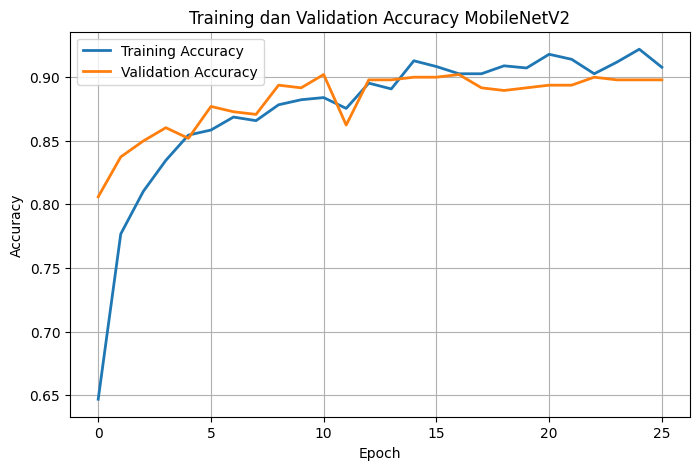

In [ ]:
# =====================================================
# GRAFIK ACCURACY
# =====================================================

plt.figure(figsize=(8,5)) # Menentukan ukuran grafik dengan lebar 8 dan tinggi 5

plt.plot( # Membuat garis grafik untuk menampilkan akurasi data training
    history.history['accuracy'], # Mengambil nilai training accuracy dari riwayat proses training
    label='Training Accuracy', # Memberikan nama "Training Accuracy" pada garis grafik
    linewidth=2 # Menentukan ketebalan garis grafik
)

plt.plot( # Membuat garis grafik untuk menampilkan akurasi data validasi
    history.history['val_accuracy'], # Mengambil nilai validation accuracy dari riwayat proses training
    label='Validation Accuracy', # Memberikan nama "Validation Accuracy" pada garis grafik
    linewidth=2 # Menentukan ketebalan garis grafik
)

plt.title('Training dan Validation Accuracy MobileNetV2') # Memberikan judul pada grafik

plt.xlabel('Epoch') # Memberikan label pada sumbu X yang menunjukkan jumlah epoch

plt.ylabel('Accuracy') # Memberikan label pada sumbu Y yang menunjukkan nilai akurasi

plt.legend() # Menampilkan keterangan untuk membedakan garis training dan validation

plt.grid(True) # Menambahkan garis bantu pada grafik agar lebih mudah dibaca

plt.show() # Menampilkan grafik

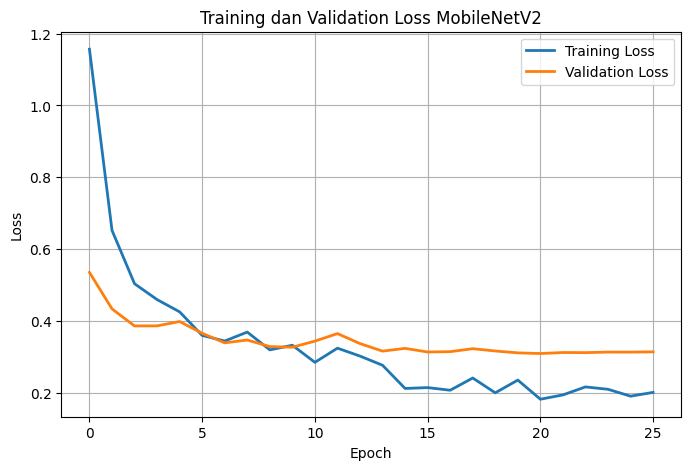

In [ ]:
# =====================================================
# GRAFIK LOSS
# =====================================================

plt.figure(figsize=(8,5)) # Menentukan ukuran grafik dengan lebar 8 dan tinggi 5

plt.plot( # Membuat garis grafik untuk menampilkan nilai loss pada data training
    history.history['loss'], # Mengambil nilai training loss dari riwayat proses training
    label='Training Loss', # Memberikan nama "Training Loss" pada garis grafik
    linewidth=2 # Menentukan ketebalan garis grafik
)

plt.plot( # Membuat garis grafik untuk menampilkan nilai loss pada data validasi
    history.history['val_loss'], # Mengambil nilai validation loss dari riwayat proses training
    label='Validation Loss', # Memberikan nama "Validation Loss" pada garis grafik
    linewidth=2 # Menentukan ketebalan garis grafik
)

plt.title('Training dan Validation Loss MobileNetV2') # Memberikan judul pada grafik

plt.xlabel('Epoch') # Memberikan label pada sumbu X yang menunjukkan jumlah epoch

plt.ylabel('Loss') # Memberikan label pada sumbu Y yang menunjukkan nilai loss

plt.legend() # Menampilkan keterangan untuk membedakan garis training dan validation

plt.grid(True) # Menambahkan garis bantu pada grafik agar grafik lebih mudah dibaca

plt.show() # Menampilkan grafik

In [ ]:
# =====================================================
# LOAD MODEL TERBAIK
# =====================================================

model.load_weights("best_mobilenetv2.keras") # Memuat bobot model terbaik yang sebelumnya telah disimpan oleh ModelCheckpoint

## ASSESS

In [ ]:
# =====================================================
# LOAD MODEL TERBAIK
# =====================================================

model.load_weights("best_mobilenetv2.keras") # Memuat bobot model terbaik yang telah disimpan sebelumnya

print("Best Model berhasil dimuat.") # Menampilkan pesan bahwa model terbaik berhasil dimuat

Best Model berhasil dimuat.


In [ ]:
# =====================================================
# EVALUASI TEST SET
# =====================================================

test_loss, test_accuracy = model.evaluate( # Mengevaluasi performa model menggunakan data testing
    test_generator, # Menggunakan test_generator sebagai sumber data pengujian
    verbose=1 # Menampilkan proses evaluasi selama model berjalan
)

print("="*45) # Menampilkan garis pemisah untuk memperjelas tampilan hasil evaluasi
print(f"Test Accuracy : {test_accuracy:.4f}") # Menampilkan nilai akurasi model pada data testing dengan 4 angka di belakang koma
print(f"Test Loss     : {test_loss:.4f}") # Menampilkan nilai loss model pada data testing dengan 4 angka di belakang koma
print("="*45) # Menampilkan garis pemisah setelah hasil evaluasi

9/9 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.8788 - loss: 0.2871
Test Accuracy : 0.8788
Test Loss     : 0.2871


In [ ]:
# =====================================================
# PREDIKSI DATA TEST
# =====================================================

test_generator.reset() # Mengatur ulang posisi generator agar prediksi dimulai dari data pertama

y_prob = model.predict(test_generator) # Menghasilkan probabilitas prediksi untuk setiap kelas pada data testing

y_pred = np.argmax(y_prob, axis=1) # Mengambil kelas dengan probabilitas tertinggi sebagai hasil prediksi

y_true = test_generator.classes # Mengambil label kelas sebenarnya dari seluruh data testing

class_names = list(test_generator.class_indices.keys()) # Mengambil nama-nama kelas dari test generator dan menyimpannya dalam bentuk list

9/9 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step


In [ ]:
# =====================================================
# CLASSIFICATION REPORT
# =====================================================

from sklearn.metrics import classification_report # Mengimpor fungsi classification_report untuk mengevaluasi performa klasifikasi model

print( # Menampilkan hasil evaluasi klasifikasi
    classification_report( # Menghasilkan laporan precision, recall, f1-score, dan support untuk setiap kelas
        y_true, # Label kelas sebenarnya dari data testing
        y_pred, # Label kelas hasil prediksi model
        target_names=class_names, # Menampilkan nama kelas pada laporan sesuai dengan class_names
        digits=4 # Menampilkan hasil metrik dengan 4 angka di belakang koma
    )
)

                     precision    recall  f1-score   support

    Anthracnose 224     0.9221    0.8353    0.8765        85
         Canker 224     0.9167    0.7333    0.8148        15
            Dot 224     0.6786    0.9500    0.7917        20
      Fruit Fly 224     0.9556    1.0000    0.9773        43
  Healthy Fruit 224     1.0000    1.0000    1.0000        25
     Phytophora 224     0.8889    0.8889    0.8889         9
       Red Rust 224     1.0000    0.8148    0.8980        27
           Scab 224     0.7500    0.8000    0.7742        15
Styler and Root 224     0.7000    0.8400    0.7636        25

           accuracy                         0.8788       264
          macro avg     0.8680    0.8736    0.8650       264
       weighted avg     0.8922    0.8788    0.8808       264



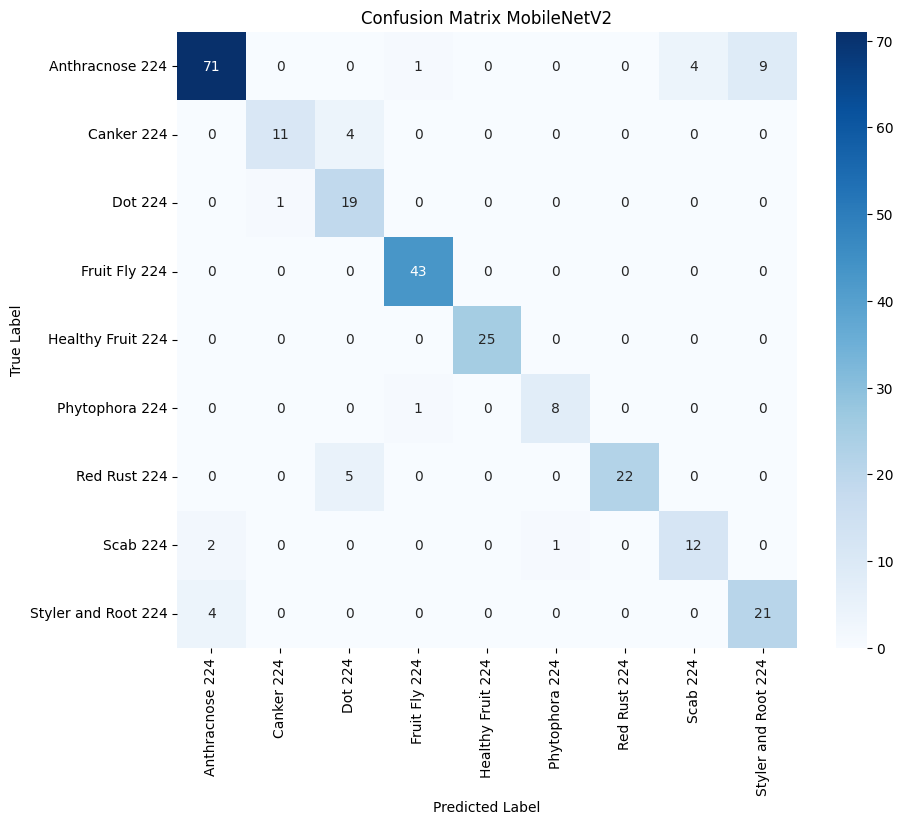

In [ ]:
# =====================================================
# CONFUSION MATRIX
# =====================================================

from sklearn.metrics import confusion_matrix # Mengimpor fungsi confusion_matrix untuk menghitung hasil prediksi benar dan salah pada setiap kelas

cm = confusion_matrix( # Membuat confusion matrix berdasarkan label sebenarnya dan hasil prediksi model
    y_true, # Label kelas sebenarnya dari data testing
    y_pred # Label kelas hasil prediksi model
)

plt.figure(figsize=(10,8)) # Menentukan ukuran gambar confusion matrix dengan lebar 10 dan tinggi 8

sns.heatmap( # Membuat confusion matrix dalam bentuk heatmap agar lebih mudah dibaca
    cm, # Data confusion matrix yang akan divisualisasikan
    annot=True, # Menampilkan angka hasil prediksi di dalam setiap sel
    fmt="d", # Menampilkan nilai dalam format bilangan bulat
    cmap="Blues", # Menggunakan gradasi warna biru untuk membedakan nilai pada setiap sel
    xticklabels=class_names, # Menampilkan nama kelas pada sumbu X sebagai label hasil prediksi
    yticklabels=class_names # Menampilkan nama kelas pada sumbu Y sebagai label sebenarnya
)

plt.title("Confusion Matrix MobileNetV2") # Memberikan judul pada confusion matrix

plt.xlabel("Predicted Label") # Memberikan label pada sumbu X yang menunjukkan kelas hasil prediksi model

plt.ylabel("True Label") # Memberikan label pada sumbu Y yang menunjukkan kelas sebenarnya

plt.xticks(rotation=90) # Memutar label pada sumbu X sebesar 90 derajat agar nama kelas lebih mudah dibaca

plt.yticks(rotation=0) # Mempertahankan label pada sumbu Y dalam posisi horizontal

plt.show() # Menampilkan confusion matrix

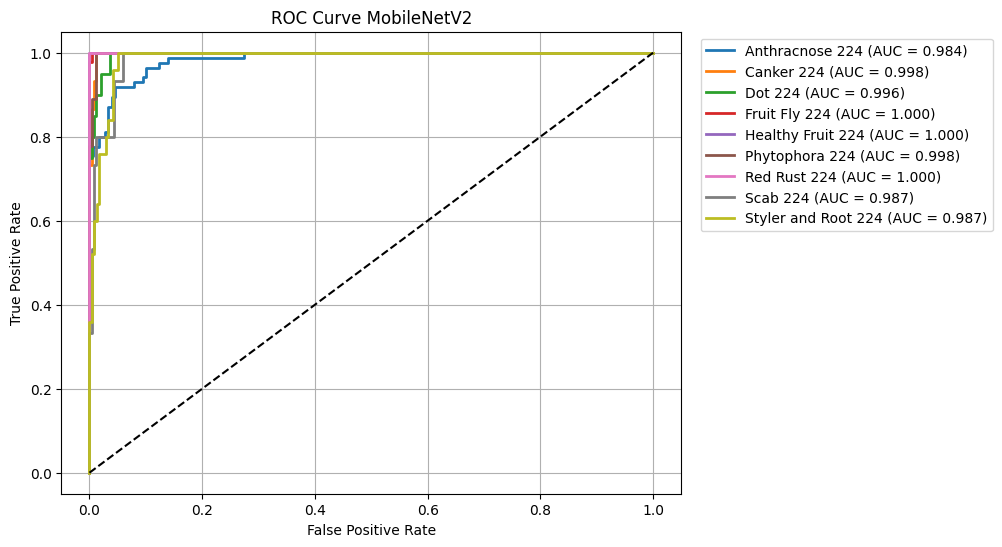

In [ ]:
# =====================================================
# ROC CURVE DAN AUC
# =====================================================

from sklearn.preprocessing import label_binarize # Mengimpor fungsi untuk mengubah label kelas menjadi format biner

from sklearn.metrics import roc_curve, auc # Mengimpor fungsi untuk menghitung ROC Curve dan nilai AUC

y_true_bin = label_binarize( # Mengubah label kelas sebenarnya menjadi format biner untuk setiap kelas
    y_true, # Menggunakan label kelas sebenarnya dari data testing
    classes=range(len(class_names))  #Menentukan daftar kelas berdasarkan jumlah kelas yang tersedia
)

plt.figure(figsize=(8,6)) # Menentukan ukuran grafik dengan lebar 8 dan tinggi 6

for i in range(len(class_names)): # Melakukan perulangan untuk menghitung ROC Curve pada setiap kelas

    fpr, tpr, _ = roc_curve( # Menghitung False Positive Rate dan True Positive Rate untuk setiap kelas
        y_true_bin[:, i], # Menggunakan label biner dari kelas ke-i sebagai nilai sebenarnya
        y_prob[:, i] # Menggunakan probabilitas prediksi model untuk kelas ke-i
    )

    roc_auc = auc(fpr, tpr) # Menghitung nilai AUC berdasarkan FPR dan TPR

    plt.plot( # Menggambar garis ROC Curve untuk setiap kelas
        fpr, # Menentukan nilai False Positive Rate pada sumbu X
        tpr,  # Menentukan nilai True Positive Rate pada sumbu Y
        lw=2, # Menentukan ketebalan garis ROC Curve
        label=f"{class_names[i]} (AUC = {roc_auc:.3f})" # Menampilkan nama kelas dan nilai AUC pada legenda
    )

plt.plot( # Membuat garis referensi diagonal sebagai pembanding performa model
    [0,1], # Menentukan nilai pada sumbu X dari 0 sampai 1
    [0,1], # Menentukan nilai pada sumbu Y dari 0 sampai 1
    linestyle="--", # Menggunakan garis putus-putus
    color="black" # Menentukan warna garis referensi menjadi hitam
)

plt.xlabel("False Positive Rate") # Memberikan label pada sumbu X

plt.ylabel("True Positive Rate") # Memberikan label pada sumbu Y

plt.title("ROC Curve MobileNetV2")  # Memberikan judul pada grafik ROC Curve

plt.legend( # Menampilkan legenda nama kelas dan nilai AUC
    bbox_to_anchor=(1.02,1), # Menentukan posisi legenda sedikit di sebelah kanan grafik
    loc="upper left" # Menentukan titik acuan posisi legenda
)

plt.grid(True) # Menambahkan garis bantu agar grafik lebih mudah dibaca

plt.show() # Menampilkan grafik ROC Curve

In [ ]:
# =====================================================
# NILAI AUC
# =====================================================

auc_macro = roc_auc_score( # Menghitung nilai AUC rata-rata untuk seluruh kelas
    y_true_bin, # Menggunakan label sebenarnya dalam format biner
    y_prob, # Menggunakan probabilitas prediksi dari model
    multi_class="ovr", # Menggunakan metode One-vs-Rest untuk klasifikasi multi-kelas
    average="macro" # Menghitung rata-rata AUC setiap kelas tanpa mempertimbangkan jumlah data tiap kelas
)

auc_weighted = roc_auc_score( # Menghitung nilai AUC dengan mempertimbangkan jumlah data pada setiap kelas
    y_true_bin, # Menggunakan label sebenarnya dalam format biner
    y_prob, # Menggunakan probabilitas prediksi dari model
    multi_class="ovr", # Menggunakan metode One-vs-Rest untuk klasifikasi multi-kelas
    average="weighted" # Menghitung rata-rata AUC dengan bobot berdasarkan jumlah data setiap kelas
)

print(f"Macro AUC    : {auc_macro:.4f}") # Menampilkan nilai Macro AUC dengan 4 angka di belakang koma
print(f"Weighted AUC : {auc_weighted:.4f}") # Menampilkan nilai Weighted AUC dengan 4 angka di belakang koma

Macro AUC    : 0.9945
Weighted AUC : 0.9925


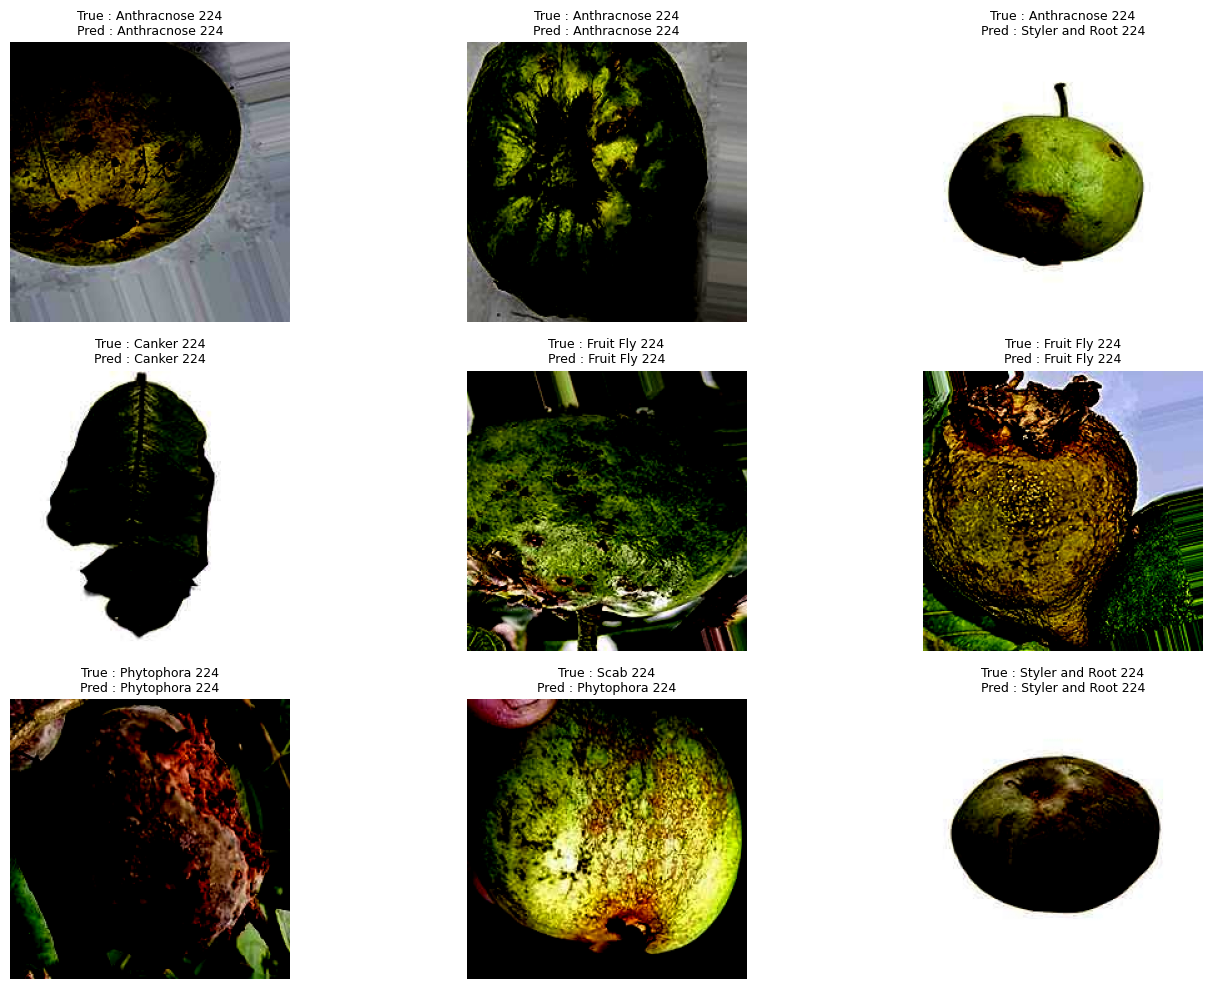

In [ ]:
# =====================================================
# VISUALISASI HASIL PREDIKSI
# =====================================================

plt.figure(figsize=(15,10)) # Membuat area gambar dengan ukuran lebar 15 dan tinggi 10

for i in range(9): # Melakukan perulangan untuk menampilkan 9 gambar hasil prediksi

    image, label = test_generator[i] # Mengambil satu batch gambar dan label dari test generator

    img = image[0] # Mengambil gambar pertama dari batch

    true_label = np.argmax(label[0]) # Mendapatkan indeks kelas sebenarnya dari label one-hot encoding

    pred = model.predict(np.expand_dims(img,0), verbose=0) # Melakukan prediksi terhadap satu gambar

    pred_label = np.argmax(pred) # Mengambil indeks kelas dengan probabilitas prediksi tertinggi

    plt.subplot(3,3,i+1) # Membuat posisi gambar pada grid 3 baris dan 3 kolom

    plt.imshow(img) # Menampilkan gambar yang akan diprediksi

    plt.axis("off") # Menyembunyikan sumbu X dan Y agar tampilan gambar lebih bersih

    plt.title(  # Menampilkan label sebenarnya dan label hasil prediksi pada judul gambar
        f"True : {class_names[true_label]}\nPred : {class_names[pred_label]}", # Menampilkan nama kelas sebenarnya dan hasil prediksi
        fontsize=9 # Menentukan ukuran font judul sebesar 9
    )

plt.tight_layout() # Mengatur jarak antar gambar agar tidak saling bertumpuk

plt.show()  # Menampilkan seluruh visualisasi hasil prediksi

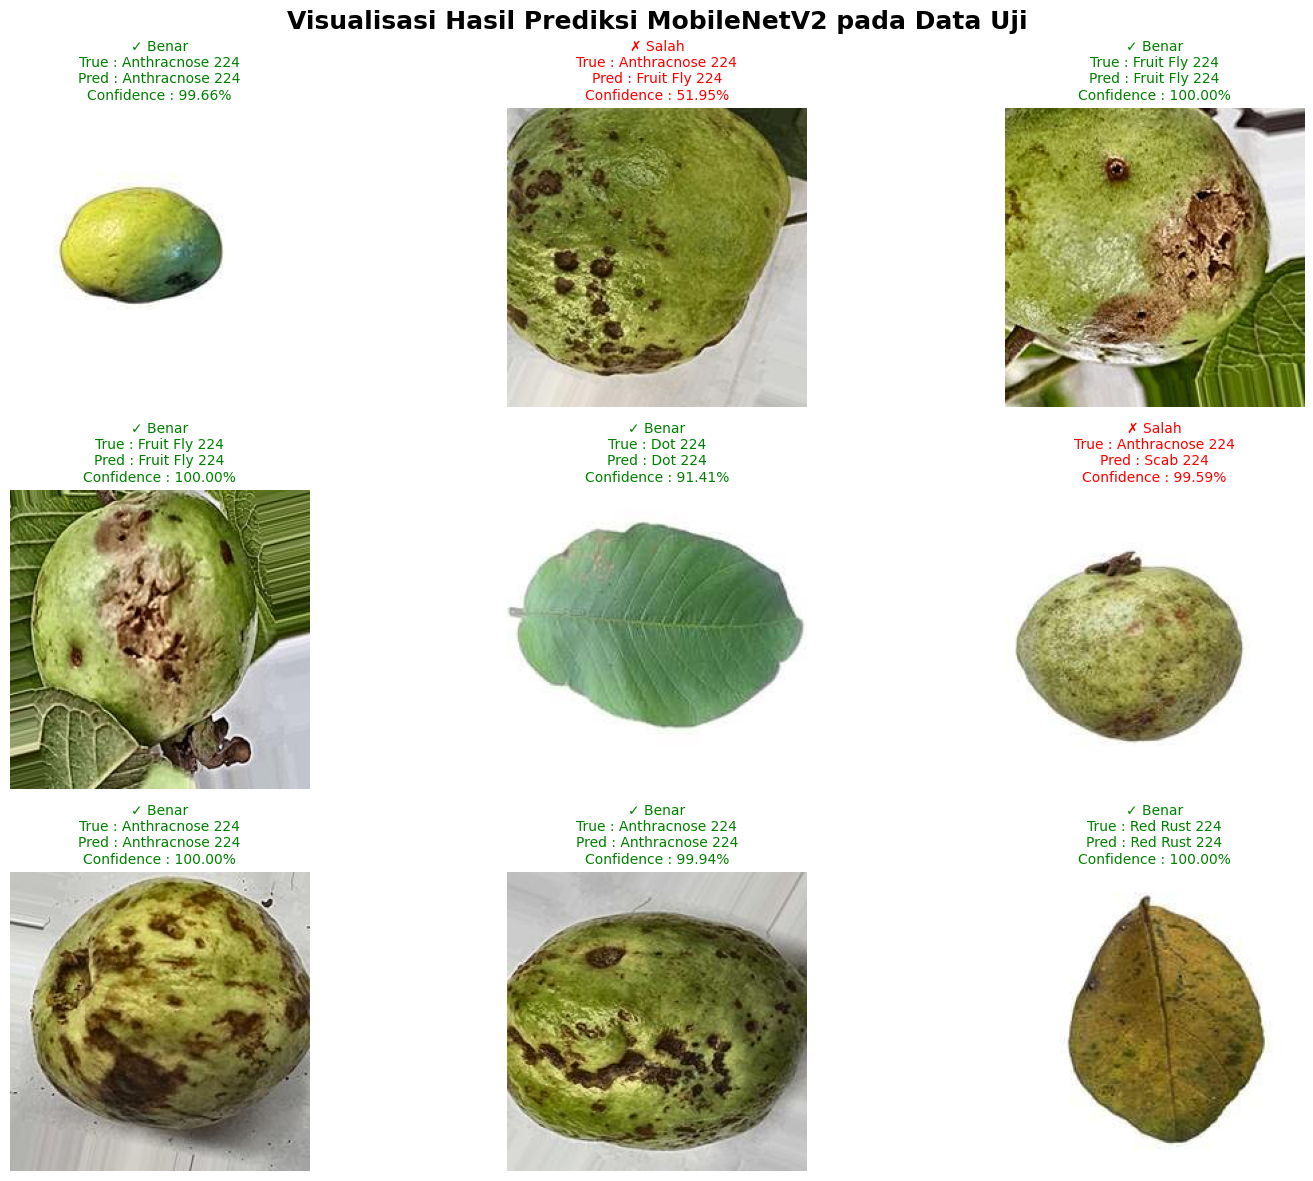

In [ ]:
# ============================================================
# VISUALISASI HASIL PREDIKSI MOBILEINETV2
# ============================================================

import random # Mengimpor library random untuk memilih gambar secara acak
import numpy as np # Mengimpor NumPy untuk pengolahan array dan perhitungan numerik
import matplotlib.pyplot as plt # Mengimpor Matplotlib untuk membuat visualisasi gambar

# Reset generator
test_generator.reset() # Mengatur ulang posisi test generator agar pembacaan data dimulai dari awal

# Prediksi seluruh data test
predictions = model.predict(test_generator, verbose=0) # Melakukan prediksi terhadap seluruh data testing

# Label prediksi
predicted_classes = np.argmax(predictions, axis=1) # Mengambil indeks kelas dengan probabilitas prediksi tertinggi

# Label asli
true_classes = test_generator.classes # Mengambil label kelas sebenarnya dari seluruh data testing

# Nama kelas
class_names = list(test_generator.class_indices.keys()) # Mengambil nama seluruh kelas dari test generator

# Path seluruh gambar
filenames = test_generator.filepaths # Mengambil lokasi/path dari seluruh file gambar pada data testing

# Ambil 9 gambar secara acak
random.seed(42) # Menentukan seed agar pemilihan gambar acak tetap sama setiap kali kode dijalankan
sample_idx = random.sample(range(len(filenames)), 9) # Memilih 9 indeks gambar secara acak dari seluruh data testing

plt.figure(figsize=(16,12)) # Membuat area visualisasi dengan ukuran lebar 16 dan tinggi 12

for i, idx in enumerate(sample_idx): # Melakukan perulangan untuk menampilkan setiap gambar yang telah dipilih

    # Load gambar
    img = tf.keras.utils.load_img( # Memuat gambar dari path file
        filenames[idx], # Menggunakan path gambar berdasarkan indeks yang dipilih
        target_size=(224,224) # Mengubah ukuran gambar menjadi 224x224 piksel sesuai input MobileNetV2
    )

    img_array = tf.keras.utils.img_to_array(img) # Mengubah gambar menjadi array NumPy

    # Simpan gambar asli untuk ditampilkan
    img_display = img_array.astype("uint8") # Mengubah tipe data gambar menjadi uint8 agar dapat ditampilkan sebagai gambar asli

    # Preprocessing MobileNetV2
    img_pre = tf.keras.applications.mobilenet_v2.preprocess_input( # Melakukan preprocessing gambar sesuai kebutuhan MobileNetV2
        np.expand_dims(img_array.copy(), axis=0) # Menambahkan dimensi batch agar gambar memiliki format yang sesuai untuk model
    )

    # Prediksi ulang
    pred = model.predict(img_pre, verbose=0) # Melakukan prediksi terhadap gambar yang telah diproses

    pred_class = np.argmax(pred) # Mengambil indeks kelas dengan probabilitas prediksi tertinggi

    confidence = np.max(pred)*100 # Mengambil probabilitas tertinggi sebagai tingkat keyakinan dalam bentuk persen

    true_class = true_classes[idx] # Mengambil label kelas sebenarnya dari gambar

    # Warna Judul
    if pred_class == true_class: # Memeriksa apakah hasil prediksi sama dengan label sebenarnya
        color = "green" # Menggunakan warna hijau jika prediksi benar
        status = "✓ Benar" # Memberikan status bahwa prediksi benar
    else: # Jika hasil prediksi berbeda dari label sebenarnya
        color = "red" # Menggunakan warna merah jika prediksi salah
        status = "✗ Salah" # Memberikan status bahwa prediksi salah

    plt.subplot(3,3,i+1) # Membuat posisi gambar pada grid 3 baris dan 3 kolom

    plt.imshow(img_display) # Menampilkan gambar dalam bentuk visual

    plt.axis("off") # Menyembunyikan sumbu X dan Y agar tampilan gambar lebih bersih

    plt.title( # Menampilkan status, label sebenarnya, hasil prediksi, dan confidence
        f"{status}\n" # Menampilkan status benar atau salah
        f"True : {class_names[true_class]}\n" # Menampilkan nama kelas sebenarnya
        f"Pred : {class_names[pred_class]}\n" # Menampilkan nama kelas hasil prediksi model
        f"Confidence : {confidence:.2f}%", # Menampilkan tingkat confidence prediksi dengan 2 angka di belakang koma
        fontsize=10, # Menentukan ukuran font judul
        color=color # Mengatur warna judul berdasarkan benar atau salahnya prediksi
    )

plt.suptitle( # Memberikan judul utama untuk keseluruhan visualisasi
    "Visualisasi Hasil Prediksi MobileNetV2 pada Data Uji", # Menentukan teks judul utama
    fontsize=18, # Menentukan ukuran font judul utama
    fontweight="bold" # Membuat judul utama menjadi tebal
)

plt.tight_layout() # Mengatur jarak antar elemen agar tidak saling bertumpuk

plt.show() # Menampilkan seluruh visualisasi hasil prediksi